# <font color='gold'>Combining all sampled course, teacher, university review text</font>


In [1]:
import os
from sampling_util.table_util import *
from matplotlib import pyplot as plt

dflist = []
file_dir = '../../data/2_sampled/sampling_output_unlabelled/'
out_filename = os.path.join('../../data/2_sampled/', 'combined_data_6.5k.csv')
#========================================

rating_stats_file = out_filename.replace('2_sampled/', '2_sampled/sampling_output_stats/').replace('.csv', f'_rating_stats.csv')
length_stats_file = out_filename.replace('2_sampled/', '2_sampled/sampling_output_stats/').replace('.csv', f'_length_stats.csv')
img_dir = '../../data/2_sampled/sampling_output_stats/'

print(f'\nInputdir:  {file_dir}\n\nOutput:   \033[032m{out_filename}\033[0m\n\nStats_1:  \033[35m{rating_stats_file}\033[0m\nStats_1:  \033[35m{length_stats_file}\033[0m\n')


Inputdir:  ../../data/2_sampled/sampling_output_unlabelled/

Output:   ../../data/2_sampled/combined_data_6.5k.csv

Stats_1:  ../../data/2_sampled/sampling_output_stats/combined_data_6.5k_rating_stats.csv
Stats_1:  ../../data/2_sampled/sampling_output_stats/combined_data_6.5k_length_stats.csv



## <font color='cornflowerblue'>1) Read all stratefied_sampled files from different sources</font>

In [2]:

file_list = sorted([filename for filename in os.listdir(file_dir) if os.path.isfile(os.path.join(file_dir, filename))])  #for root, dirs, files in os.walk('OUTPUT'):
dflist = [pd.read_csv(os.path.join(file_dir, filename)) for filename in file_list]

print(file_list)
tempdict = {'_&_'.join(str(x) for x in df.source.unique()): len(df) for df in dflist}

print(f"\ndflist len = \033[36m{len(dflist)}\033[0m\n\033[36m{tempdict}\033[0m\n", sep='\n')

output = pd.concat(dflist, ignore_index=False, sort=False)
print(f'Unique datasources in df: \033[36m{output.source.unique()}\033[0m\n')

if len(output == sum(len(df) for df in dflist)) and set(id for df in dflist for id in df['id'])==set(output.id.unique()):
    print(f"\033[42m\033[30mAll good!!!   len = {len(output)}\033[0m\n")
    
output

['1_He_2020_RMP_v2(N=3000).csv', '2_Uwaterloo_course_reviews(N=3000).csv', '3_UExeter_uni_reviews(N=500).csv']

dflist len = 3
{'data1_19145': 3000, 'data2_14810': 3000, 'data3_557': 500}

Unique datasources in df: ['data1_19145' 'data2_14810' 'data3_557']

All good!!!   len = 6500



,type,source,id,rating,num_token,sample_criteria,review_text,rating_bin,rating_cat,length_bin
0,teacher review,data1_19145,1_45_2639_18911,5.0,74,"Pos_(61.0, 81.0]",Dr. Zhong is a really good chemistry teacher. ...,"(4.0, 5.0]",Pos,"(61.0, 81.0]"
1,teacher review,data1_19145,1_206_452_3440,1.5,56,"Neg_(41.0, 61.0]",I have her for behav. neuro and she is terribl...,"(0.999, 2.5]",Neg,"(41.0, 61.0]"
2,teacher review,data1_19145,1_93_2121_1031,1.0,77,"Neg_(61.0, 81.0]",the prof. is real crap. it is a shame that the...,"(0.999, 2.5]",Neg,"(61.0, 81.0]"
3,teacher review,data1_19145,1_89_50_4831,3.5,42,"Conf/Neu_(41.0, 61.0]",He is a great guy and is pretty funny in class...,"(2.5, 4.0]",Conf/Neu,"(41.0, 61.0]"
4,teacher review,data1_19145,1_88_396_5468,1.0,44,"Neg_(41.0, 61.0]","Plain and simple, this guy is HORRIBLE! He not...","(0.999, 2.5]",Neg,"(41.0, 61.0]"
...,...,...,...,...,...,...,...,...,...,...
495,university review,data3_557,3_343_393_290,4.8,15,"Pos_(0.999, 21.0]","University is absolutely as good as expected, ...","(4.0, 5.0]",Pos,"(0.999, 21.0]"
496,university review,data3_557,3_118_412_64,5.0,25,"Pos_(21.0, 41.0]","Brilliant University, perfect fit for me even ...","(4.0, 5.0]",Pos,"(21.0, 41.0]"
497,university review,data3_557,3_334_178_52,4.2,12,"Pos_(0.999, 21.0]",Great uni! Loads of food outlets and study are...,"(4.0, 5.0]",Pos,"(0.999, 21.0]"
498,university review,data3_557,3_427_169_213,4.6,16,"Pos_(0.999, 21.0]","The campus is amazing, people are all fantasti...","(4.0, 5.0]",Pos,"(0.999, 21.0]"


## <font color='cornflowerblue'>2) Examine distributions</font>

In [3]:
count_table(output, 'type')

,type,count
0,course review,3000
1,teacher review,3000
2,university review,500


In [4]:
count_table(output, 'rating_cat')

,rating_cat,count
0,Pos,3901
1,Neg,1731
2,Conf/Neu,823
3,[NA],45


In [5]:
count_table(output, 'length_bin', sort_by='length_bin', ascending=True)

,length_bin,count
0,"(0.999, 21.0]",1826
1,"(21.0, 41.0]",1566
3,"(41.0, 61.0]",1286
2,"(61.0, 81.0]",1340
4,"(81.0, 101.0]",179
5,"(101.0, 121.0]",101
6,"(121.0, 141.0]",63
7,"(141.0, 161.0]",42
9,"(161.0, 181.0]",22
8,"(181.0, 201.0]",22


In [6]:
rating_stats = get_sample_distribution(output, ['type', 'rating_cat', 'id'], 'rating_cat', 'type', 'id', 'count')
rating_stats.to_csv(rating_stats_file, index=False)
print(f'\nLength_stats written to \033[33m{rating_stats_file}\033[0m, done~!\n')

rating_stats


Length_stats written to ../../data/2_sampled/sampling_output_stats/combined_data_6.5k_rating_stats.csv, done~!



type,rating_cat,course review,course review (%),teacher review,teacher review (%),university review,university review (%),TOTAL,TOTAL (%)
0,Conf/Neu,NaN,NaN,696.0,23.20,127.0,25.4,823.0,12.66
1,Neg,979.0,32.63,743.0,24.77,9.0,1.8,1731.0,26.63
2,Pos,1976.0,65.87,1561.0,52.03,364.0,72.8,3901.0,60.02
3,[NA],45.0,1.50,NaN,NaN,NaN,NaN,45.0,0.69
4,TOTAL,3000.0,100.00,3000.0,100.00,500.0,100.0,6500.0,100.00


In [7]:
length_stats = get_sample_distribution(output, ['type', 'length_bin', 'id'], 'length_bin', 'type', 'id', 'count')
length_stats.to_csv(length_stats_file, index=False)
print(f'\nLength_stats written to \033[33m{length_stats_file}\033[0m, done~!\n')

length_stats


Length_stats written to ../../data/2_sampled/sampling_output_stats/combined_data_6.5k_length_stats.csv, done~!



type,length_bin,course review,course review (%),teacher review,teacher review (%),university review,university review (%),TOTAL,TOTAL (%)
0,"(0.999, 21.0]",1049.0,34.97,480.0,16.00,297.0,59.4,1826.0,28.09
7,"(21.0, 41.0]",793.0,26.43,662.0,22.07,111.0,22.2,1566.0,24.09
18,"(41.0, 61.0]",460.0,15.33,776.0,25.87,50.0,10.0,1286.0,19.78
21,"(61.0, 81.0]",270.0,9.00,1057.0,35.23,13.0,2.6,1340.0,20.62
22,"(81.0, 101.0]",147.0,4.90,25.0,0.83,7.0,1.4,179.0,2.75
1,"(101.0, 121.0]",95.0,3.17,NaN,NaN,6.0,1.2,101.0,1.55
2,"(121.0, 141.0]",55.0,1.83,NaN,NaN,8.0,1.6,63.0,0.97
3,"(141.0, 161.0]",40.0,1.33,NaN,NaN,2.0,0.4,42.0,0.65
4,"(161.0, 181.0]",21.0,0.70,NaN,NaN,1.0,0.2,22.0,0.34
5,"(181.0, 201.0]",19.0,0.63,NaN,NaN,3.0,0.6,22.0,0.34


In [8]:
lengthxrating_stats = output[['type', 'length_bin', 'rating_cat', 'id']]

lengthxrating_stats = lengthxrating_stats.pivot_table(index='length_bin', columns=['type', 'rating_cat'], values='id', aggfunc='nunique').reset_index()

lengthxrating_stats

type            length_bin course review              teacher review         \
rating_cat                           Neg    Pos  [NA]       Conf/Neu    Neg   
0            (0.999, 21.0]         351.0  680.0  18.0           87.0  103.0   
1           (101.0, 121.0]          32.0   61.0   2.0            NaN    NaN   
2           (121.0, 141.0]          20.0   35.0   NaN            NaN    NaN   
3           (141.0, 161.0]          14.0   25.0   1.0            NaN    NaN   
4           (161.0, 181.0]           8.0   13.0   NaN            NaN    NaN   
5           (181.0, 201.0]           5.0   13.0   1.0            NaN    NaN   
6           (201.0, 221.0]           5.0    8.0   NaN            NaN    NaN   
7             (21.0, 41.0]         241.0  541.0  11.0          141.0  144.0   
8           (221.0, 241.0]           6.0    4.0   NaN            NaN    NaN   
9           (241.0, 261.0]           3.0    4.0   NaN            NaN    NaN   
10          (261.0, 281.0]           2.0    2.0   NaN            NaN    NaN   
11          (281.0, 301.0]           2.0    2.0   NaN            NaN    NaN   
12          (301.0, 321.0]           2.0    1.0   NaN            NaN    NaN   
13          (321.0, 341.0]           1.0    1.0   NaN            NaN    NaN   
14          (341.0, 361.0]           1.0    1.0   NaN            NaN    NaN   
15          (361.0, 381.0]           1.0    NaN   NaN            NaN    NaN   
16          (381.0, 401.0]           1.0    NaN   NaN            NaN    NaN   
17          (401.0, 421.0]           1.0    1.0   NaN            NaN    NaN   
18            (41.0, 61.0]         142.0  310.0   8.0          186.0  186.0   
19          (461.0, 481.0]           1.0    NaN   NaN            NaN    NaN   
20          (501.0, 521.0]           1.0    NaN   NaN            NaN    NaN   
21            (61.0, 81.0]          86.0  182.0   2.0          275.0  303.0   
22           (81.0, 101.0]          53.0   92.0   2.0            7.0    7.0   

type              university review              
rating_cat    Pos          Conf/Neu  Neg    Pos  
0           290.0              64.0  3.0  230.0  
1             NaN               2.0  1.0    3.0  
2             NaN               2.0  NaN    6.0  
3             NaN               2.0  NaN    NaN  
4             NaN               NaN  NaN    1.0  
5             NaN               NaN  NaN    3.0  
6             NaN               1.0  NaN    1.0  
7           377.0              30.0  2.0   79.0  
8             NaN               NaN  NaN    NaN  
9             NaN               NaN  NaN    NaN  
10            NaN               NaN  NaN    NaN  
11            NaN               NaN  NaN    NaN  
12            NaN               NaN  NaN    NaN  
13            NaN               NaN  NaN    NaN  
14            NaN               NaN  NaN    NaN  
15            NaN               NaN  NaN    NaN  
16            NaN               NaN  NaN    NaN  
17            NaN               NaN  NaN    NaN  
18          404.0              18.0  2.0   30.0  
19            NaN               NaN  NaN    NaN  
20            NaN               NaN  NaN    NaN  
21          479.0               5.0  NaN    8.0  
22           11.0               3.0  1.0    3.0

## <font color='cornflowerblue'>graphs</font>

In [9]:
output.loc[output.rating_cat=='[NA]']

,type,source,id,rating,num_token,sample_criteria,review_text,rating_bin,rating_cat,length_bin
161,course review,data2_14810,2_4795_1076,NaN,42,"[NA]_(41.0, 61.0]",Basically high school physics (plus some - rol...,[NA],[NA],"(41.0, 61.0]"
176,course review,data2_14810,2_4830_1698,NaN,19,"[NA]_(0.999, 21.0]",Very easy to get above 80% if you do all the a...,[NA],[NA],"(0.999, 21.0]"
214,course review,data2_14810,2_5734_1162,NaN,21,"[NA]_(0.999, 21.0]","""WTF, man I just wanted to learn how to progra...",[NA],[NA],"(0.999, 21.0]"
257,course review,data2_14810,2_7394_831,NaN,6,"[NA]_(0.999, 21.0]",practising the questions is important!,[NA],[NA],"(0.999, 21.0]"
312,course review,data2_14810,2_4215_777,NaN,1,"[NA]_(0.999, 21.0]",boring,[NA],[NA],"(0.999, 21.0]"
340,course review,data2_14810,2_6375_1709,NaN,33,"[NA]_(21.0, 41.0]",The textbook is very helpful for this course. ...,[NA],[NA],"(21.0, 41.0]"
419,course review,data2_14810,2_12634_1187,NaN,186,"[NA]_(181.0, 201.0]",This course is broken down into 3 distinct sec...,[NA],[NA],"(181.0, 201.0]"
502,course review,data2_14810,2_3594_821,NaN,109,"[NA]_(101.0, 121.0]","As many people said, it is essentially a revie...",[NA],[NA],"(101.0, 121.0]"
548,course review,data2_14810,2_3593_821,NaN,57,"[NA]_(41.0, 61.0]","If you did accounting in high school, there's ...",[NA],[NA],"(41.0, 61.0]"
584,course review,data2_14810,2_2756_232,NaN,51,"[NA]_(41.0, 61.0]",During the course the difficulty level of the ...,[NA],[NA],"(41.0, 61.0]"


,length_bin,count
0,"(0.999, 21.0]",1826
1,"(21.0, 41.0]",1566
3,"(41.0, 61.0]",1286
2,"(61.0, 81.0]",1340
4,"(81.0, 101.0]",179
5,"(101.0, 121.0]",101
6,"(121.0, 141.0]",63
7,"(141.0, 161.0]",42
9,"(161.0, 181.0]",22
8,"(181.0, 201.0]",22



Image saved to ../../data/2_sampled/sampling_output_stats/combined - count by length.png


<Axes: xlabel='Count', ylabel='length_bin'>

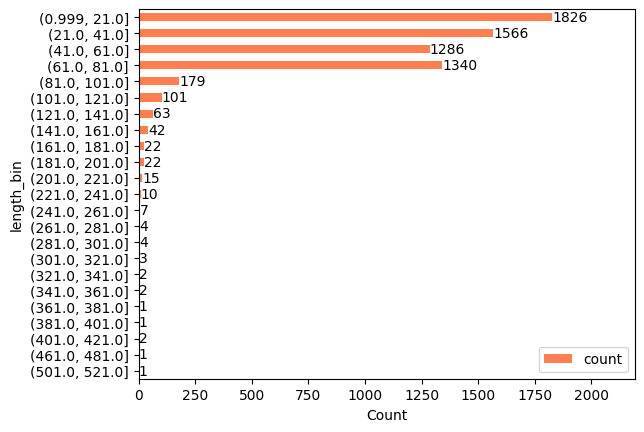

In [10]:
#=================================
img_file_1 = 'combined - count by length.png'
img1_path = os.path.join(img_dir, img_file_1)
#=================================

lengthdf = count_table(output, target_cols='length_bin', sort_by='length_bin', ascending=True)
display(lengthdf)
print()

graphdf = lengthdf.copy()
graphdf.loc[:,'length_start'] = graphdf.length_bin.astype(str).str.split(',').str[0].str.replace('(', '').str.strip().astype('float64')
graphdf = graphdf.sort_values(by='length_start', ascending=False)
# display(graphdf)
ax1 = graphdf.plot.barh(x='length_bin', y='count', xlabel='Count', color='coral', table=False, rot=0)
ax1.bar_label(ax1.containers[0]) 
ax1.margins(x=0.2) 

plt.savefig(img1_path, bbox_inches='tight', dpi=1080)
print(f'\33[033mImage saved to {img1_path}\33[0m')

ax1


,rating_cat,count,%
3,[NA],45,0.006923
0,Pos,3901,0.600154
1,Neg,1731,0.266308
2,Conf/Neu,823,0.126615



Image saved to ../../data/2_sampled/sampling_output_stats/combined - count by rating.png


<Axes: xlabel='Count', ylabel='rating_cat'>

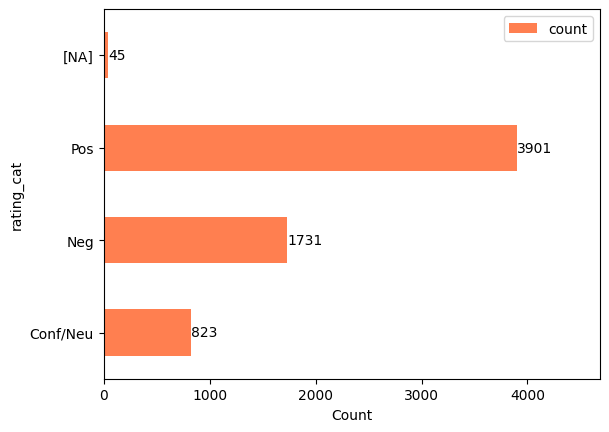

In [11]:
#=================================
img_file_2 = 'combined - count by rating.png'
img1_path = os.path.join(img_dir, img_file_2)
#=================================

ratingdf = count_table(output, target_cols='rating_cat', sort_by='rating_cat', ascending=False)
ratingdf.loc[:, '%'] = ratingdf['count']/ratingdf['count'].sum()
display(ratingdf)
print()

graphdf = ratingdf.copy().sort_values(by='rating_cat', ascending=True)
# display(graphdf)
ax1 = graphdf.plot.barh(x='rating_cat', y='count', xlabel='Count', color='coral', table=False, rot=0)
ax1.bar_label(ax1.containers[0]) 
ax1.margins(x=0.2) 

plt.savefig(img1_path, bbox_inches='tight', dpi=1080)
print(f'\33[033mImage saved to {img1_path}\33[0m')

ax1


## <font color='cornflowerblue'>3) Write to file</font>

In [12]:
output.to_csv(out_filename, index=False)

print(f'Combined file printed to \033[033m{out_filename}\033[0m, done!')

Combined file printed to ../../data/2_sampled/combined_data_6.5k.csv, done!


In [13]:
output

,type,source,id,rating,num_token,sample_criteria,review_text,rating_bin,rating_cat,length_bin
0,teacher review,data1_19145,1_45_2639_18911,5.0,74,"Pos_(61.0, 81.0]",Dr. Zhong is a really good chemistry teacher. ...,"(4.0, 5.0]",Pos,"(61.0, 81.0]"
1,teacher review,data1_19145,1_206_452_3440,1.5,56,"Neg_(41.0, 61.0]",I have her for behav. neuro and she is terribl...,"(0.999, 2.5]",Neg,"(41.0, 61.0]"
2,teacher review,data1_19145,1_93_2121_1031,1.0,77,"Neg_(61.0, 81.0]",the prof. is real crap. it is a shame that the...,"(0.999, 2.5]",Neg,"(61.0, 81.0]"
3,teacher review,data1_19145,1_89_50_4831,3.5,42,"Conf/Neu_(41.0, 61.0]",He is a great guy and is pretty funny in class...,"(2.5, 4.0]",Conf/Neu,"(41.0, 61.0]"
4,teacher review,data1_19145,1_88_396_5468,1.0,44,"Neg_(41.0, 61.0]","Plain and simple, this guy is HORRIBLE! He not...","(0.999, 2.5]",Neg,"(41.0, 61.0]"
...,...,...,...,...,...,...,...,...,...,...
495,university review,data3_557,3_343_393_290,4.8,15,"Pos_(0.999, 21.0]","University is absolutely as good as expected, ...","(4.0, 5.0]",Pos,"(0.999, 21.0]"
496,university review,data3_557,3_118_412_64,5.0,25,"Pos_(21.0, 41.0]","Brilliant University, perfect fit for me even ...","(4.0, 5.0]",Pos,"(21.0, 41.0]"
497,university review,data3_557,3_334_178_52,4.2,12,"Pos_(0.999, 21.0]",Great uni! Loads of food outlets and study are...,"(4.0, 5.0]",Pos,"(0.999, 21.0]"
498,university review,data3_557,3_427_169_213,4.6,16,"Pos_(0.999, 21.0]","The campus is amazing, people are all fantasti...","(4.0, 5.0]",Pos,"(0.999, 21.0]"
